In [3]:
from sklearn.datasets import make_regression
import pandas as pd
import numpy as np

import plotly.express as px
import plotly.graph_objects as go

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [10]:
X,y = make_regression(n_samples=100, n_features=2, n_informative=2, n_targets=1, noise=50)

In [13]:


X, y = make_regression(
    n_samples=100,
    n_features=2,
    n_informative=2,
    n_targets=1,
    noise=50,
    random_state=42
)

df = pd.DataFrame({
    'feature_1': X[:, 0],
    'feature_2': X[:, 1],
    'target': y,
})

print(df.head())
print(df.shape)


   feature_1  feature_2      target
0  -1.191303   0.656554  -22.779796
1   0.058209  -1.142970 -107.569629
2   0.586857   2.190456  201.122932
3   0.473238  -0.072829    1.480178
4   0.738467   0.171368  111.798503
(100, 3)


In [14]:
df.head()

,feature_1,feature_2,target
0,-1.191303,0.656554,-22.779796
1,0.058209,-1.142970,-107.569629
2,0.586857,2.190456,201.122932
3,0.473238,-0.072829,1.480178
4,0.738467,0.171368,111.798503


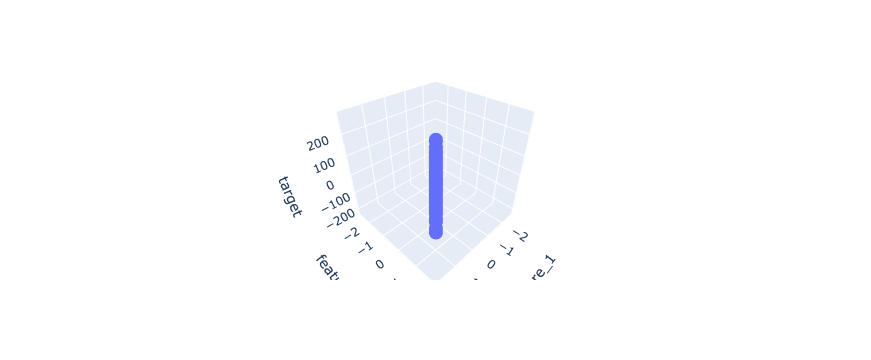

In [17]:
fig = px.scatter_3d(df, x='feature_1', y='feature_1', z='target')
fig.show()

In [22]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=3)

In [23]:
from sklearn.linear_model import LinearRegression

In [24]:
lr = LinearRegression()

In [25]:
lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[81.06,72.39]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5.364
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,2
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](2,)","[9.17,7.63]"


In [26]:
y_pred = lr.predict(X_test)

In [28]:
print("MEA",mean_absolute_error(y_test,y_pred))
print("MSE",mean_squared_error(y_test,y_pred))
print("R2_Score",r2_score(y_test,y_pred))

MEA 47.0876578106196
MSE 3639.6081061143377
R2_Score 0.655121125764055


In [31]:

import numpy as np

x = np.linspace(-5, 5, 10)
y = np.linspace(-5, 5, 10)

xGrid, yGrid = np.meshgrid(x, y)

# Create the input data first
final = np.vstack((
    xGrid.ravel(),
    yGrid.ravel()
)).T

# Predict using the trained Linear Regression model
z_final = lr.predict(final).reshape(10, 10)

z = z_final


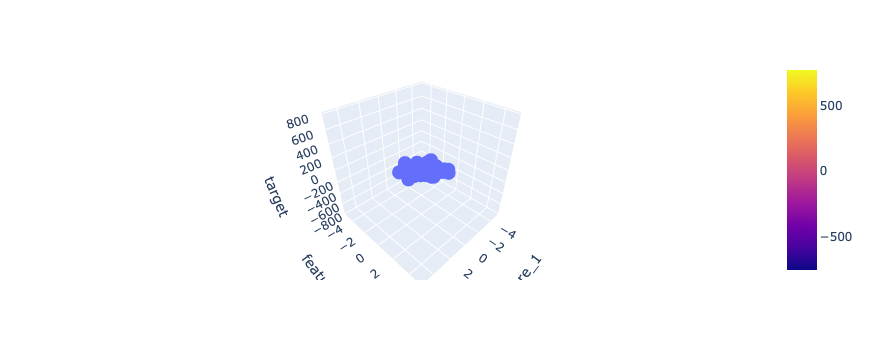

In [33]:
fig = px.scatter_3d(df, x='feature_1', y='feature_2', z='target')

fig.add_trace(go.Surface(x = x, y = y, z =z ))

fig.show()

In [34]:

lr.coef_

array([81.05675748, 72.39437821])

In [35]:
lr.intercept_

np.float64(5.3638090720905645)